In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Garbage_Classification"
)

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

for folder in [
    "dataset",
    "checkpoints",
    "models",
    "evaluation",
    "logs"
]:
    (PROJECT_DIR / folder).mkdir(exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Folders created successfully!")

Project directory: /content/drive/MyDrive/Garbage_Classification
Folders created successfully!


In [ ]:
from pathlib import Path

DATASET_DIR = PROJECT_DIR / "dataset" / "raw"

for class_dir in sorted(DATASET_DIR.iterdir()):
    if class_dir.is_dir():
        images = [
            f for f in class_dir.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
        ]
        print(f"{class_dir.name}: {len(images)} images")

glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images


In [ ]:
# Check corrupted images

from PIL import Image
from collections import Counter

valid_images = []
corrupted_images = []
image_sizes = Counter()

for class_dir in sorted(DATASET_DIR.iterdir()):

    if not class_dir.is_dir():
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() not in [
            ".jpg", ".jpeg", ".png", ".bmp"
        ]:
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()

            # Reopen to read image dimensions
            with Image.open(image_path) as img:
                image_sizes[img.size] += 1

            valid_images.append(image_path)

        except Exception as e:
            corrupted_images.append({
                "file": str(image_path),
                "error": str(e)
            })

print("Total images checked:", len(valid_images) + len(corrupted_images))
print("Valid images:", len(valid_images))
print("Corrupted images:", len(corrupted_images))

print("\nMost common image dimensions:")
for size, count in image_sizes.most_common(10):
    print(f"{size}: {count}")

Total images checked: 1987
Valid images: 1987
Corrupted images: 0

Most common image dimensions:
(512, 384): 1987




* saari images ka resolution 512 × 384 hai. Ye useful hai kyunki abhi dataset mein image dimensions consistent hain.
* Lekin ek baat samajhna: model training ke waqt hum images ko generally 224 × 224 resize karenge (EfficientNet-B0 ke standard input size ke liye). Original images ko modify nahi karenge.


     Class  Image Count
0    glass          501
1    metal          410
2    paper          594
3  plastic          482

Total images: 1987


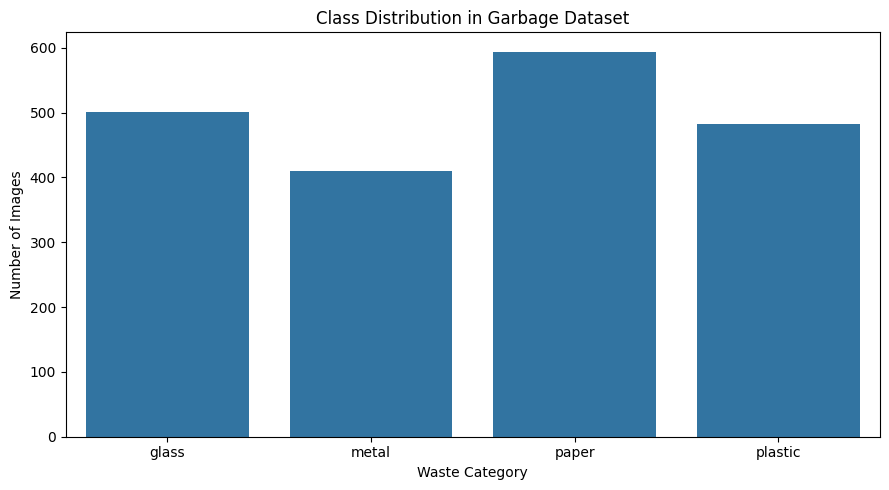

In [ ]:
# Class distribution visualize karna

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

class_counts = {}

for class_dir in sorted(DATASET_DIR.iterdir()):
    if class_dir.is_dir():
        count = len([
            f for f in class_dir.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
        ])
        class_counts[class_dir.name] = count

distribution_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image Count"]
)

print(distribution_df)
print("\nTotal images:", distribution_df["Image Count"].sum())

plt.figure(figsize=(9, 5))

sns.barplot(
    data=distribution_df,
    x="Class",
    y="Image Count"
)

plt.title("Class Distribution in Garbage Dataset")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

NameError: name 'classes' is not defined

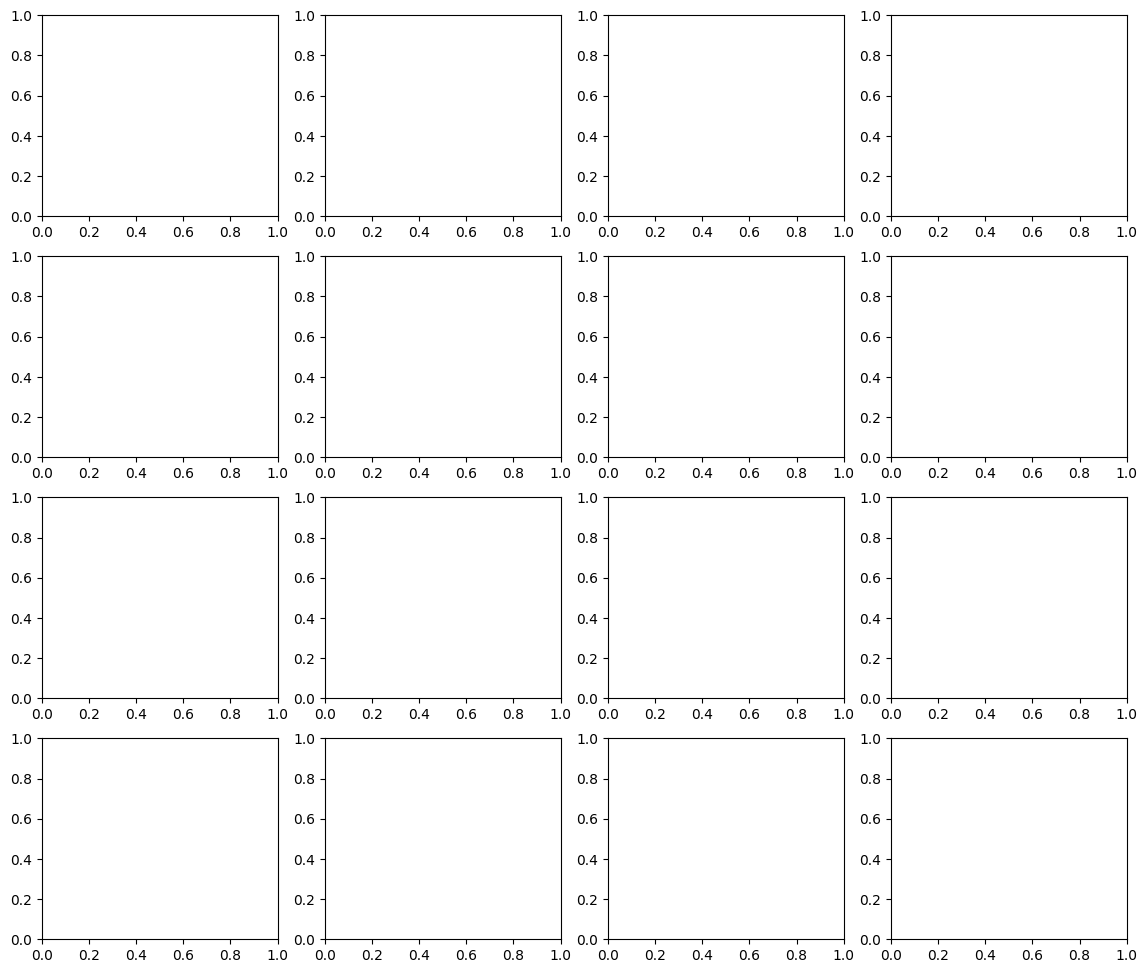

In [ ]:
# Sample images visualize karna

import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(14, 12)
)

for row, class_name in enumerate(classes):

    class_path = DATASET_DIR / class_name

    image_files = [
        file for file in class_path.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    selected_images = random.sample(image_files, 4)

    for col, image_path in enumerate(selected_images):

        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name.capitalize())
        axes[row, col].axis("off")

plt.suptitle("Sample Images from Each Waste Category", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

# Reconnect Drive if required
from google.colab import drive
drive.mount('/content/drive')

# Restore project paths
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Garbage_Classification"
)

DATASET_DIR = PROJECT_DIR / "dataset" / "raw"

# Restore class names
classes = sorted([
    folder.name
    for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
])

print("Dataset path:", DATASET_DIR)
print("Classes:", classes)
print("Number of classes:", len(classes))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset path: /content/drive/MyDrive/Garbage_Classification/dataset/raw
Classes: ['glass', 'metal', 'paper', 'plastic']
Number of classes: 4


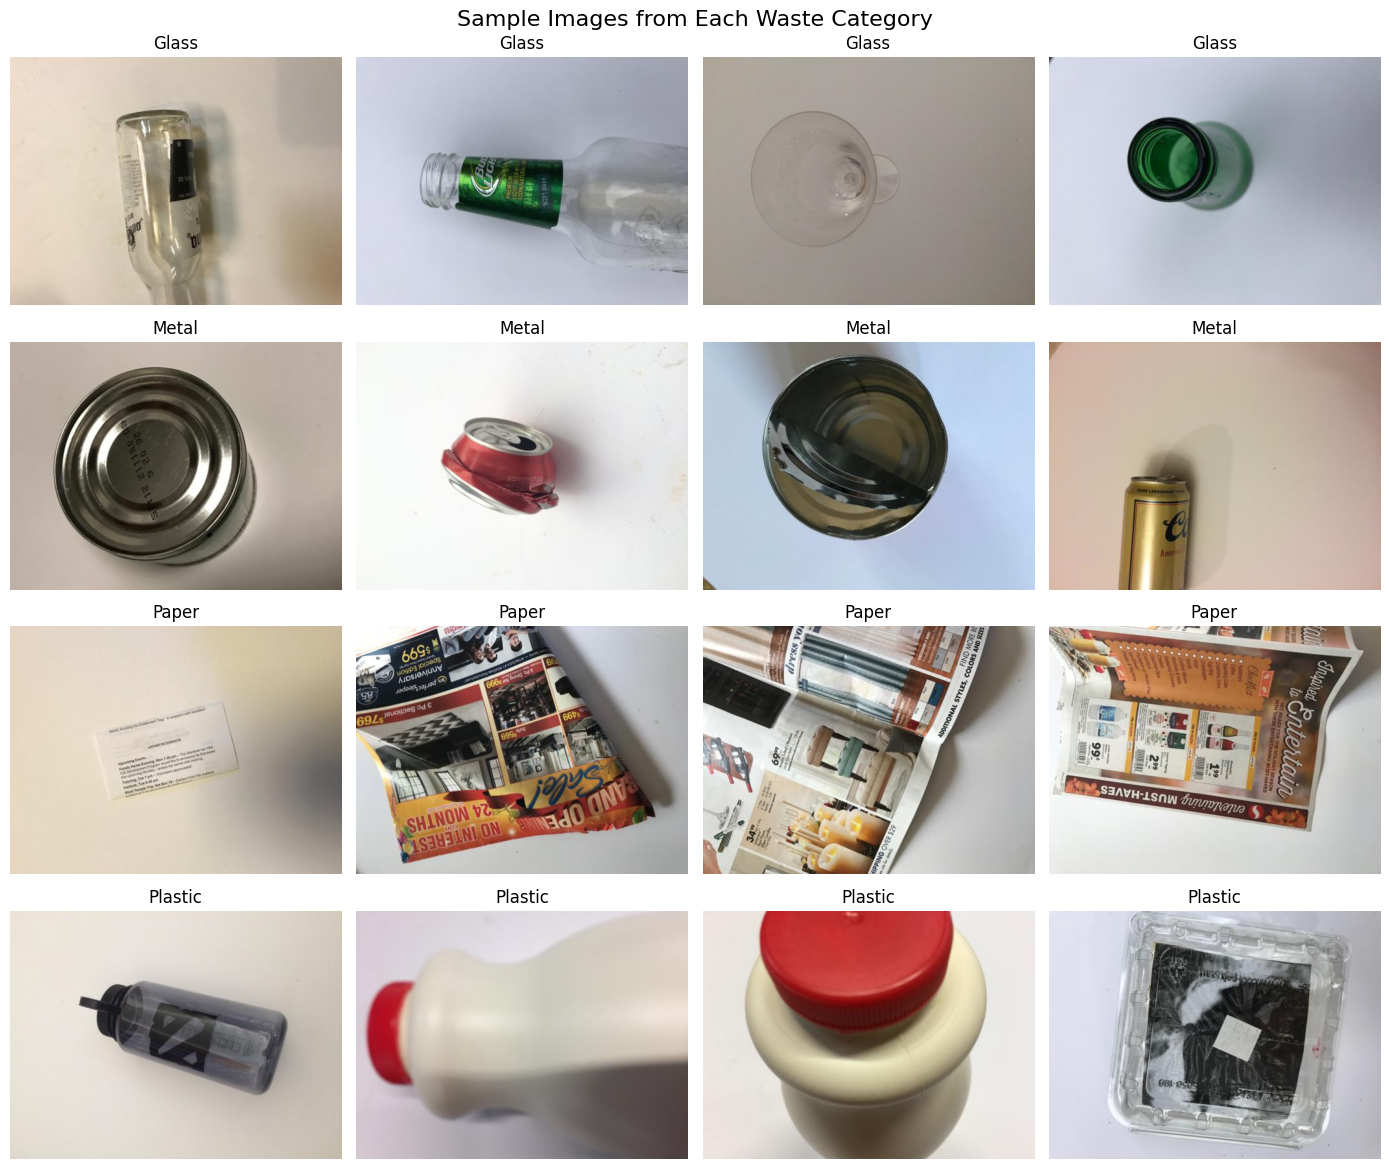

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

# Close any previously created empty figures
plt.close("all")

fig, axes = plt.subplots(
    nrows=len(classes),
    ncols=4,
    figsize=(14, 12)
)

for row, class_name in enumerate(classes):

    class_path = DATASET_DIR / class_name

    image_files = [
        file for file in class_path.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
    ]

    selected_images = random.sample(image_files, 4)

    for col, image_path in enumerate(selected_images):

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(class_name.capitalize())
        axes[row, col].axis("off")

plt.suptitle(
    "Sample Images from Each Waste Category",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
# Dataset metadata CSV save karna

import pandas as pd
from PIL import Image

records = []

for class_name in classes:

    class_path = DATASET_DIR / class_name

    for image_path in class_path.iterdir():

        if image_path.suffix.lower() not in [
            ".jpg", ".jpeg", ".png", ".bmp"
        ]:
            continue

        with Image.open(image_path) as img:

            records.append({
                "image_path": str(image_path),
                "label": class_name,
                "width": img.width,
                "height": img.height,
                "mode": img.mode
            })

metadata_df = pd.DataFrame(records)

metadata_path = PROJECT_DIR / "evaluation" / "dataset_metadata.csv"

metadata_df.to_csv(metadata_path, index=False)

print("Metadata saved:", metadata_path)
print("Total records:", len(metadata_df))

display(metadata_df.head())

Metadata saved: /content/drive/MyDrive/Garbage_Classification/evaluation/dataset_metadata.csv
Total records: 1987


,image_path,label,width,height,mode
0,/content/drive/MyDrive/Garbage_Classification/...,glass,512,384,RGB
1,/content/drive/MyDrive/Garbage_Classification/...,glass,512,384,RGB
2,/content/drive/MyDrive/Garbage_Classification/...,glass,512,384,RGB
3,/content/drive/MyDrive/Garbage_Classification/...,glass,512,384,RGB
4,/content/drive/MyDrive/Garbage_Classification/...,glass,512,384,RGB


In [ ]:
# Metadata verify karna

print("Image dimensions:")
print(metadata_df[["width", "height"]].describe())

print("\nImage modes:")
print(metadata_df["mode"].value_counts())

print("\nClass distribution:")
print(metadata_df["label"].value_counts())

Image dimensions:
        width  height
count  1987.0  1987.0
mean    512.0   384.0
std       0.0     0.0
min     512.0   384.0
25%     512.0   384.0
50%     512.0   384.0
75%     512.0   384.0
max     512.0   384.0

Image modes:
mode
RGB    1987
Name: count, dtype: int64

Class distribution:
label
paper      594
glass      501
plastic    482
metal      410
Name: count, dtype: int64




*   Dataset splitting as 70:15:15
* 70% -> training(1,390), 15% -> validation(298) and 15% -> testing(299)



In [ ]:
# Reproducible dataset splitting

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    metadata_df,
    test_size=0.30,
    random_state=42,
    stratify=metadata_df["label"]
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

Training images: 1390
Validation images: 298
Testing images: 299
Total: 1987


In [ ]:
# Save split CSVs in Google Drive

split_dir = PROJECT_DIR / "evaluation"
split_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(split_dir / "train.csv", index=False)
val_df.to_csv(split_dir / "validation.csv", index=False)
test_df.to_csv(split_dir / "test.csv", index=False)

print("All splits saved successfully!")

print("Training:", (split_dir / "train.csv").exists())
print("Validation:", (split_dir / "validation.csv").exists())
print("Testing:", (split_dir / "test.csv").exists())

All splits saved successfully!
Training: True
Validation: True
Testing: True


In [ ]:
# Verify class distribution in every split

print("TRAINING DISTRIBUTION")
print(train_df["label"].value_counts().sort_index())

print("\nVALIDATION DISTRIBUTION")
print(val_df["label"].value_counts().sort_index())

print("\nTESTING DISTRIBUTION")
print(test_df["label"].value_counts().sort_index())

TRAINING DISTRIBUTION
label
glass      350
metal      287
paper      416
plastic    337
Name: count, dtype: int64

VALIDATION DISTRIBUTION
label
glass      75
metal      62
paper      89
plastic    72
Name: count, dtype: int64

TESTING DISTRIBUTION
label
glass      76
metal      61
paper      89
plastic    73
Name: count, dtype: int64


In [ ]:
# Check data leakage

train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

print("Train-Validation overlap:", len(train_paths & val_paths))
print("Train-Test overlap:", len(train_paths & test_paths))
print("Validation-Test overlap:", len(val_paths & test_paths))

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0


In [1]:
# GPU SHIFTING AND VERIFYING

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
    print("GPU count:", torch.cuda.device_count())
else:
    print("GPU not detected by PyTorch")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU name: Tesla T4
CUDA version: 13.0
GPU count: 1


In [2]:
# Drive aur saved checkpoints verify karna
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Garbage_Classification"
)

DATASET_DIR = PROJECT_DIR / "dataset" / "raw"
SPLIT_DIR = PROJECT_DIR / "evaluation"

print("Project exists:", PROJECT_DIR.exists())
print("Dataset exists:", DATASET_DIR.exists())

for filename in ["train.csv", "validation.csv", "test.csv"]:
    path = SPLIT_DIR / filename
    print(filename, ":", path.exists())

Mounted at /content/drive
Project exists: True
Dataset exists: True
train.csv : True
validation.csv : True
test.csv : True


**Training configuration**

* Ab hum EfficientNet-B0 use karenge as our primary model.

In [3]:
# Check TorchVision
# EfficientNet-B0 implementation aur pretrained weights torchvision se milenge

import torch
import torchvision

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

print("EfficientNet-B0 imported successfully!")
print("Pretrained weights:", EfficientNet_B0_Weights.DEFAULT)


PyTorch: 2.14.1+cu130
TorchVision: 0.29.1+cu130
EfficientNet-B0 imported successfully!
Pretrained weights: EfficientNet_B0_Weights.IMAGENET1K_V1


In [4]:
# Save environment information

import json

environment_info = {
    "pytorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": torch.cuda.get_device_name(0),
    "cuda_version": torch.version.cuda,
    "input_size": 224,
    "num_classes": 4,
    "random_seed": 42
}

env_path = PROJECT_DIR / "evaluation" / "environment.json"

with open(env_path, "w") as f:
    json.dump(environment_info, f, indent=4)

print("Environment details saved:", env_path)

Environment details saved: /content/drive/MyDrive/Garbage_Classification/evaluation/environment.json


* Hum EfficientNet-B0 ko scratch se train nahi karenge. Hum Transfer Learning use karenge.
* Iska basic workflow:
  * Image input: 224 × 224 × 3.
  * Feature extraction: pretrained EfficientNet-B0 image ke patterns identify karega.
  * Global Average Pooling: extracted feature maps ko compact feature representation mein convert karega
  * Classifier: original 1,000 ImageNet outputs ki jagah hamare 4 waste categories predict karega.
* Transfer learning ka benefit: Model pehle se edges, textures, shapes aur object patterns seekh chuka hai. Humein us knowledge ko waste classification ke liye adapt karna hai.

**Hamari training strategy**
* Phase 1: Pretrained backbone freeze karke classifier train karenge.
* Phase 2: Selected backbone layers unfreeze karke fine-tuning karenge.
* Validation loss ke basis par best model save karenge.
* Test dataset ko final evaluation tak untouched rakhenge.

**Image preprocessing**

In [5]:
# Imports and class mapping
import torch
import pandas as pd

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from PIL import Image
from pathlib import Path

# Fixed class order
classes = ["glass", "metal", "paper", "plastic"]

class_to_idx = {
    class_name: index
    for index, class_name in enumerate(classes)
}

idx_to_class = {
    index: class_name
    for class_name, index in class_to_idx.items()
}

print("Class mapping:", class_to_idx)

Class mapping: {'glass': 0, 'metal': 1, 'paper': 2, 'plastic': 3}


In [6]:
# Define image transformations
IMAGE_SIZE = 224

# ImageNet normalization values
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Training and evaluation transformations created!")

Training and evaluation transformations created!


In [7]:
# Create custom Dataset class

class GarbageDataset(Dataset):

    def __init__(self, csv_path, transform=None):

        self.data = pd.read_csv(csv_path)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image_path = row["image_path"]
        label = row["label"]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = class_to_idx[label]

        return image, label

In [8]:
# Create datasets and DataLoaders
train_dataset = GarbageDataset(
    SPLIT_DIR / "train.csv",
    transform=train_transform
)

val_dataset = GarbageDataset(
    SPLIT_DIR / "validation.csv",
    transform=eval_transform
)

test_dataset = GarbageDataset(
    SPLIT_DIR / "test.csv",
    transform=eval_transform
)

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 87
Validation batches: 19
Testing batches: 19


In [9]:
# Verify one batch

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)
print("GPU available:", torch.cuda.is_available())

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Labels: tensor([0, 0, 3, 0, 0, 0, 0, 2, 0, 2, 0, 3, 0, 2, 2, 0])
GPU available: True


* Aur labels mein 0, 1, 2, 3 hamare four waste categories ko represent  karte hain.

**Why do we use DataLoader?**
* Dataset class ek-ek image load karna jaanti hai. DataLoader multiple images ko batches mein organize karta hai, shuffling manage karta hai aur efficient loading provide karta hai.

* For example, 1,390 training images aur batch size 16 ke saath approximately 87 batches per epoch honge.

**Next — EfficientNet-B0 architecture**
* Ab hum pretrained EfficientNet-B0 load karke uska original classifier replace karenge.

In [10]:
# Load pretrained model
import torch
import torch.nn as nn

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 182MB/s]

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


In [11]:
# Freeze pretrained backbone
for param in model.features.parameters():
    param.requires_grad = False

print("Backbone frozen successfully!")

Backbone frozen successfully!


**Why**
* Phase 1 mein pretrained feature extractor ke weights change nahi honge. Hum sirf apne waste classification task ke liye classifier train karenge.

In [12]:
# Replace classifier
num_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(num_features, 4)
)

model = model.to(device)

print(model.classifier)
print("Model device:", next(model.parameters()).device)

Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=4, bias=True)
)
Model device: cuda:0


Ab final layer 4 outputs generate karegi:
Output index	Class
* 0	Glass
* 1	Metal
* 2	Paper
* 3	Plastic

In [13]:
# Verify trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print(
    "Trainable percentage:",
    round(trainable_params / total_params * 100, 2),
    "%"
)

Total parameters: 4012672
Trainable parameters: 5124
Trainable percentage: 0.13 %


* Trainiable parameters -> 1280 x 4 + 4 = 5124
* 1280: EfficientNet se aane wale features.
* 4: Hamari waste categories.
* 4: Bias parameters.

**Training configuration**

In [14]:
# Set reproducibility
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Random seeds configured!")

Random seeds configured!


In [15]:
# Configure loss and optimizer
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Scheduler:", scheduler)

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)
Scheduler: <torch.optim.lr_scheduler.ReduceLROnPlateau object at 0x7a6b02ab3230>


In [16]:
# Define training configuration

EPOCHS = 10
BEST_VAL_LOSS = float("inf")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = PROJECT_DIR / "models" / "best_model.pth"

print("Epochs:", EPOCHS)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Best model path:", BEST_MODEL_PATH)

Epochs: 10
Checkpoint directory: /content/drive/MyDrive/Garbage_Classification/checkpoints
Best model path: /content/drive/MyDrive/Garbage_Classification/models/best_model.pth


In [17]:
# Save initial checkpoint
# Training se pehle model ki current state Drive mein save karenge

initial_checkpoint = {
    "epoch": 0,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "best_val_loss": BEST_VAL_LOSS,
    "class_to_idx": class_to_idx,
    "idx_to_class": idx_to_class,
    "seed": SEED
}

INITIAL_CHECKPOINT_PATH = CHECKPOINT_DIR / "initial_checkpoint.pth"

torch.save(
    initial_checkpoint,
    INITIAL_CHECKPOINT_PATH
)

print("Initial checkpoint saved successfully!")
print("Path:", INITIAL_CHECKPOINT_PATH)

Initial checkpoint saved successfully!
Path: /content/drive/MyDrive/Garbage_Classification/checkpoints/initial_checkpoint.pth


**Training loop**
* Hum 10 epochs train karenge. Har epoch ke baad:
  * Training loss aur accuracy calculate hogi.
  * Validation loss aur accuracy calculate hogi.
  * Learning-rate scheduler update hoga.
  * latest_checkpoint.pth save hoga.
  * Validation loss improve hone par best_model.pth update hoga
  * Training metrics CSV mein save honge.

In [18]:
# Training functions
from tqdm.auto import tqdm
import pandas as pd
import torch
import os

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    # Backbone frozen hai, classifier train hoga
    running_loss = 0.0
    correct = 0
    total = 0

    scaler = train_one_epoch.scaler

    for images, labels in tqdm(loader, desc="Training", leave=False):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


train_one_epoch.scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)


@torch.no_grad()
def evaluate_model(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, desc="Validation", leave=False):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [19]:
# Resume support and checkpoint saving
import os

LATEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "latest_checkpoint.pth"
LOG_PATH = PROJECT_DIR / "logs" / "training_log.csv"

LOG_PATH.parent.mkdir(parents=True, exist_ok=True)

start_epoch = 0
best_val_loss = float("inf")
history = []

resume_path = (
    LATEST_CHECKPOINT_PATH
    if LATEST_CHECKPOINT_PATH.exists()
    else INITIAL_CHECKPOINT_PATH
)

checkpoint = torch.load(
    resume_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

if "scheduler_state_dict" in checkpoint:
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

if "scaler_state_dict" in checkpoint:
    train_one_epoch.scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

start_epoch = checkpoint["epoch"]
best_val_loss = checkpoint["best_val_loss"]

if LOG_PATH.exists():
    history = pd.read_csv(LOG_PATH).to_dict("records")

print("Resume source:", resume_path)
print("Starting from epoch:", start_epoch + 1)
print("Best validation loss:", best_val_loss)

Resume source: /content/drive/MyDrive/Garbage_Classification/checkpoints/initial_checkpoint.pth
Starting from epoch: 1
Best validation loss: inf


In [20]:
# Actual training

for epoch in range(start_epoch, EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("-" * 40)

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc * 100:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc * 100:.2f}%")
    print(f"Learning Rate: {current_lr:.6f}")

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss

        best_checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "class_to_idx": class_to_idx,
            "best_val_loss": best_val_loss
        }

        torch.save(best_checkpoint, BEST_MODEL_PATH)
        print("Best model updated!")

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "learning_rate": current_lr
    })

    # Save training history
    pd.DataFrame(history).to_csv(LOG_PATH, index=False)

    # Save latest checkpoint after every epoch
    latest_checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": train_one_epoch.scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "class_to_idx": class_to_idx,
        "idx_to_class": idx_to_class,
        "seed": SEED
    }

    temp_path = CHECKPOINT_DIR / "latest_checkpoint.tmp"

    torch.save(latest_checkpoint, temp_path)
    os.replace(temp_path, LATEST_CHECKPOINT_PATH)

    print("Latest checkpoint saved successfully!")
    print(f"Completed epoch: {epoch + 1}/{EPOCHS}")

print("\nTraining completed!")


Epoch 1/10
----------------------------------------


Training:   0%|          | 0/87 [00:00<?, ?it/s]

Validation:   0%|          | 0/19 [00:00<?, ?it/s]

Train Loss: 0.9875
Train Accuracy: 65.04%
Validation Loss: 0.7803
Validation Accuracy: 71.81%
Learning Rate: 0.001000
Best model updated!
Latest checkpoint saved successfully!
Completed epoch: 1/10

Epoch 2/10
----------------------------------------


Training:   0%|          | 0/87 [00:00<?, ?it/s]

Validation:   0%|          | 0/19 [00:00<?, ?it/s]

... (32 outputs left out)

Training:   0%|          | 0/87 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a6b33878900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7a6b33878900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()
    self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

Validation:   0%|          | 0/19 [00:00<?, ?it/s]

Train Loss: 0.4494
Train Accuracy: 82.95%
Validation Loss: 0.5290
Validation Accuracy: 81.54%
Learning Rate: 0.001000
Best model updated!
Latest checkpoint saved successfully!
Completed epoch: 10/10

Training completed!


In [21]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders recreated successfully!")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders recreated successfully!
Train batches: 87
Validation batches: 19
Test batches: 19


In [22]:
print("Best model exists:", BEST_MODEL_PATH.exists())
print("Latest checkpoint exists:", LATEST_CHECKPOINT_PATH.exists())
print("Training log exists:", LOG_PATH.exists())

best = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("Best epoch:", best["epoch"])
print("Best validation loss:", best["best_val_loss"])

Best model exists: True
Latest checkpoint exists: True
Training log exists: True
Best epoch: 10
Best validation loss: 0.5289984777469763


**Phase 2 — Fine-tuning.**

In [23]:
  # Load Phase 1 best model and unfreeze layers

# Load the best Phase 1 model
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Phase 1 best model loaded!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])


# Freeze the complete feature extractor first
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze deeper EfficientNet blocks
for param in model.features[6:].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True


# Move model to GPU
model = model.to(device)


# Count trainable and total parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nFine-tuning configuration:")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Frozen parameters:", f"{total_params - trainable_params:,}")
print("Unfrozen feature blocks: 6, 7, 8")


Phase 1 best model loaded!
Best epoch: 10
Best validation loss: 0.5289984777469763

Fine-tuning configuration:
Total parameters: 4,012,672
Trainable parameters: 3,160,864
Frozen parameters: 851,808
Unfrozen feature blocks: 6, 7, 8


In [24]:
# Configure Phase 2 optimizer

# Phase 2: Optimizer configuration

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.features[6:].parameters(),
            "lr": 1e-5
        },
        {
            "params": model.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Phase 2 optimizer configured!")
print("Feature extractor LR:", optimizer.param_groups[0]["lr"])
print("Classifier LR:", optimizer.param_groups[1]["lr"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])


Phase 2 optimizer configured!
Feature extractor LR: 1e-05
Classifier LR: 0.0001
Weight decay: 0.0001


In [25]:
# Phase 2 training configuration

# Phase 2 training configuration

PHASE2_EPOCHS = 10

PHASE2_BEST_MODEL_PATH = PROJECT_DIR / "models" / "phase2_best_model.pth"
PHASE2_LATEST_CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "phase2_latest_checkpoint.pth"
PHASE2_LOG_PATH = PROJECT_DIR / "logs" / "phase2_training_log.csv"

best_val_loss_phase2 = float("inf")
phase2_history = []

# Create a fresh GradScaler for Phase 2
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

print("Phase 2 training configuration ready!")
print("Epochs:", PHASE2_EPOCHS)
print("Best model path:", PHASE2_BEST_MODEL_PATH)
print("Latest checkpoint path:", PHASE2_LATEST_CHECKPOINT_PATH)
print("Training log path:", PHASE2_LOG_PATH)
print("Initial best validation loss:", best_val_loss_phase2)


Phase 2 training configuration ready!
Epochs: 10
Best model path: /content/drive/MyDrive/Garbage_Classification/models/phase2_best_model.pth
Latest checkpoint path: /content/drive/MyDrive/Garbage_Classification/checkpoints/phase2_latest_checkpoint.pth
Training log path: /content/drive/MyDrive/Garbage_Classification/logs/phase2_training_log.csv
Initial best validation loss: inf


In [27]:
train_one_epoch.scaler = scaler

In [29]:

@torch.no_grad()
def evaluate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Evaluation function defined successfully!")


Evaluation function defined successfully!


In [30]:
# Training scaler verify karo
train_one_epoch.scaler = scaler
print("Phase 2 scaler connected successfully!")

Phase 2 scaler connected successfully!


In [32]:
# Phase 2 training loop


import os
import pandas as pd
from tqdm.auto import tqdm

for epoch in range(1, PHASE2_EPOCHS + 1):

    print(f"\n{'='*55}")
    print(f"PHASE 2 - EPOCH {epoch}/{PHASE2_EPOCHS}")
    print(f"{'='*55}")

    # Training
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Validation
    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    # Update learning rate scheduler
    scheduler.step(val_loss)

    # Store epoch metrics
    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "feature_lr": optimizer.param_groups[0]["lr"],
        "classifier_lr": optimizer.param_groups[1]["lr"]
    }

    phase2_history.append(epoch_record)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")

    # Save best model
    if val_loss < best_val_loss_phase2:
        best_val_loss_phase2 = val_loss

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "class_to_idx": class_to_idx,
                "best_val_loss": best_val_loss_phase2,
                "val_accuracy": val_acc
            },
            PHASE2_BEST_MODEL_PATH
        )

        print("Best Phase 2 model saved!")

    # Save latest checkpoint
    checkpoint_path = str(PHASE2_LATEST_CHECKPOINT_PATH) + ".tmp"

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_loss": best_val_loss_phase2,
            "class_to_idx": class_to_idx
        },
        checkpoint_path
    )

    os.replace(checkpoint_path, PHASE2_LATEST_CHECKPOINT_PATH)

    # Save training history
    pd.DataFrame(phase2_history).to_csv(
        PHASE2_LOG_PATH,
        index=False
    )

    print("Latest checkpoint saved!")
    print(f"Best validation loss so far: {best_val_loss_phase2:.4f}")

print("\nPhase 2 training completed!")



PHASE 2 - EPOCH 1/10


Training:   0%|          | 0/87 [00:00<?, ?it/s]

Train Loss: 0.3860
Train Accuracy: 0.86%
Validation Loss: 0.4856
Validation Accuracy: 82.55%
Best Phase 2 model saved!
Latest checkpoint saved!
Best validation loss so far: 0.4856

PHASE 2 - EPOCH 2/10


Training:   0%|          | 0/87 [00:00<?, ?it/s]

Train Loss: 0.3796
Train Accuracy: 0.86%
Validation Loss: 0.4518
Validation Accuracy: 84.23%
Best Phase 2 model saved!
Latest checkpoint saved!
Best validation loss so far: 0.4518

PHASE 2 - EPOCH 3/10


Training:   0%|          | 0/87 [00:00<?, ?it/s]

... (11 outputs left out)

Training:   0%|          | 0/87 [00:00<?, ?it/s]

Train Loss: 0.2738
Train Accuracy: 0.90%
Validation Loss: 0.4100
Validation Accuracy: 86.91%
Best Phase 2 model saved!
Latest checkpoint saved!
Best validation loss so far: 0.4100

PHASE 2 - EPOCH 10/10


Training:   0%|          | 0/87 [00:00<?, ?it/s]

Train Loss: 0.2490
Train Accuracy: 0.92%
Validation Loss: 0.4057
Validation Accuracy: 84.90%
Best Phase 2 model saved!
Latest checkpoint saved!
Best validation loss so far: 0.4057

Phase 2 training completed!


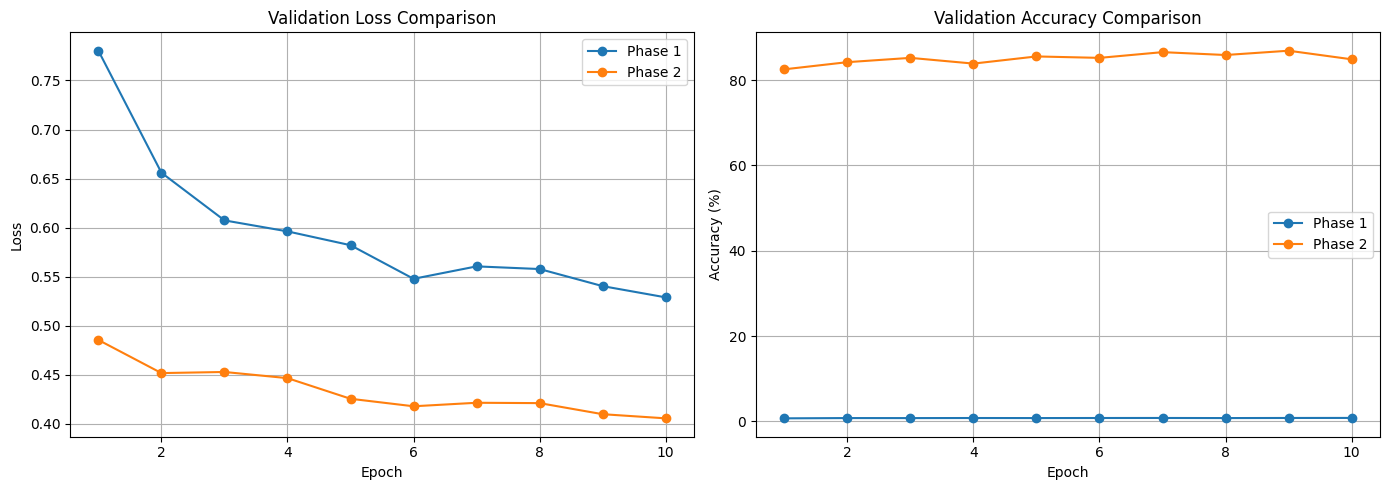

In [33]:
# Training curves


import matplotlib.pyplot as plt
import pandas as pd

phase1_df = pd.read_csv(LOG_PATH)
phase2_df = pd.read_csv(PHASE2_LOG_PATH)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss comparison
axes[0].plot(
    phase1_df["epoch"],
    phase1_df["val_loss"],
    marker="o",
    label="Phase 1"
)

axes[0].plot(
    phase2_df["epoch"],
    phase2_df["val_loss"],
    marker="o",
    label="Phase 2"
)

axes[0].set_title("Validation Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy comparison
axes[1].plot(
    phase1_df["epoch"],
    phase1_df["val_accuracy"],
    marker="o",
    label="Phase 1"
)

axes[1].plot(
    phase2_df["epoch"],
    phase2_df["val_accuracy"],
    marker="o",
    label="Phase 2"
)

axes[1].set_title("Validation Accuracy Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


Phase 1 validation accuracy range:
71.81208053691275 to 81.54362416107382

Phase 2 validation accuracy range:
82.5503355704698 to 86.91275167785236


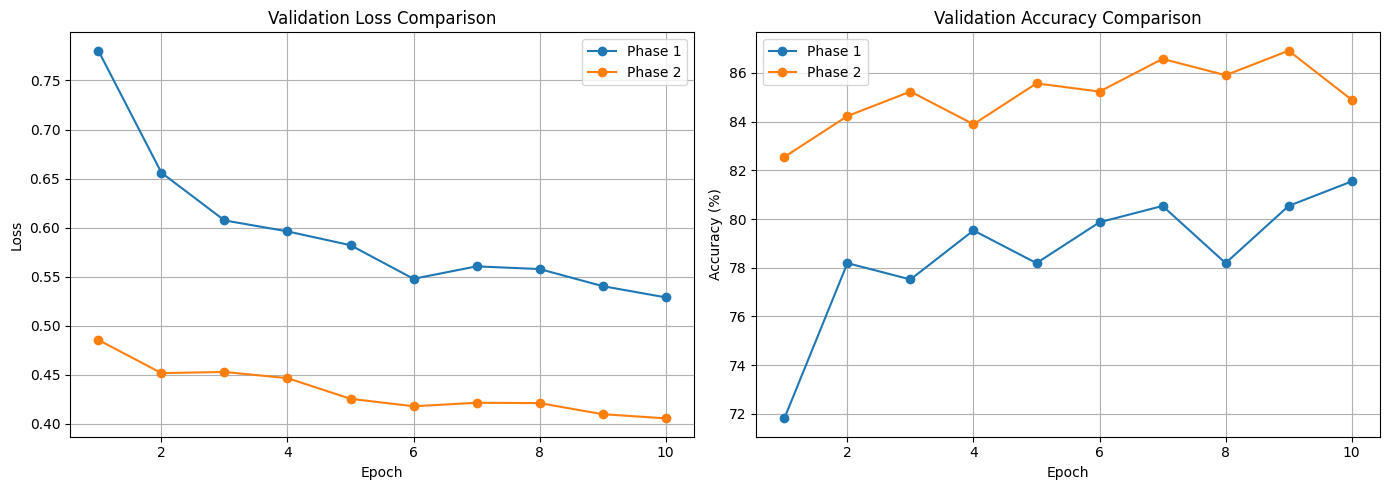

In [34]:
# Corrected accuracy comparison

# Normalize accuracy values to percentage scale

phase1_plot = phase1_df.copy()
phase2_plot = phase2_df.copy()

for df in [phase1_plot, phase2_plot]:
    if df["val_accuracy"].max() <= 1.0:
        df["val_accuracy"] = df["val_accuracy"] * 100

print("Phase 1 validation accuracy range:")
print(phase1_plot["val_accuracy"].min(), "to",
      phase1_plot["val_accuracy"].max())

print("\nPhase 2 validation accuracy range:")
print(phase2_plot["val_accuracy"].min(), "to",
      phase2_plot["val_accuracy"].max())


# Plot corrected comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    phase1_plot["epoch"], phase1_plot["val_loss"],
    marker="o", label="Phase 1"
)
axes[0].plot(
    phase2_plot["epoch"], phase2_plot["val_loss"],
    marker="o", label="Phase 2"
)
axes[0].set_title("Validation Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    phase1_plot["epoch"], phase1_plot["val_accuracy"],
    marker="o", label="Phase 1"
)
axes[1].plot(
    phase2_plot["epoch"], phase2_plot["val_accuracy"],
    marker="o", label="Phase 2"
)
axes[1].set_title("Validation Accuracy Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [35]:
# Final model load karo

# Load the best Phase 2 model

phase2_checkpoint = torch.load(
    PHASE2_BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(phase2_checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Final candidate model loaded successfully!")
print("Best epoch:", phase2_checkpoint["epoch"])
print("Best validation loss:", phase2_checkpoint["best_val_loss"])
print("Validation accuracy:", phase2_checkpoint["val_accuracy"])


Final candidate model loaded successfully!
Best epoch: 10
Best validation loss: 0.4057372536435223
Validation accuracy: 84.8993288590604


FINAL TEST RESULTS
Test Images: 299
Test Accuracy: 90.30%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       glass     0.9189    0.8947    0.9067        76
       metal     0.8382    0.9344    0.8837        61
       paper     0.9444    0.9551    0.9497        89
     plastic     0.8955    0.8219    0.8571        73

    accuracy                         0.9030       299
   macro avg     0.8993    0.9015    0.8993       299
weighted avg     0.9043    0.9030    0.9027       299



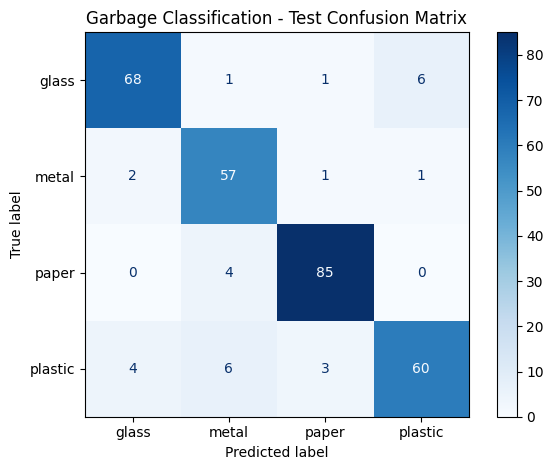

In [36]:
# Test dataset evaluation

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Class names in correct index order
idx_to_class = {
    index: name for name, index in class_to_idx.items()
}

class_names = [
    idx_to_class[i] for i in range(len(idx_to_class))
]

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate metrics
test_accuracy = accuracy_score(all_labels, all_predictions)

print("FINAL TEST RESULTS")
print("=" * 45)
print(f"Test Images: {len(all_labels)}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print("=" * 45)

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Garbage Classification - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [37]:
# Model export


# Export final Phase 2 model for web application

import torch
import json

FINAL_MODEL_PATH = PROJECT_DIR / "models" / "garbage_classifier_final.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_to_idx": class_to_idx,
        "idx_to_class": idx_to_class,
        "architecture": "EfficientNet-B0",
        "input_size": 224,
        "normalization_mean": [0.485, 0.456, 0.406],
        "normalization_std": [0.229, 0.224, 0.225]
    },
    FINAL_MODEL_PATH
)

print("Final model exported successfully!")
print("Model path:", FINAL_MODEL_PATH)
print("Architecture: EfficientNet-B0")
print("Classes:", list(class_to_idx.keys()))


Final model exported successfully!
Model path: /content/drive/MyDrive/Garbage_Classification/models/garbage_classifier_final.pth
Architecture: EfficientNet-B0
Classes: ['glass', 'metal', 'paper', 'plastic']
